# Advanced Algorithms: NP-Completeness and Reductions

> **Prerequisite:** [`dsa/01` Complexity analysis](../dsa/01_complexity_analysis_and_recursion.ipynb) (Big-O), [`dsa/09` Dynamic programming](../dsa/09_dynamic_programming.ipynb) (0/1 knapsack) and [`classical_ai/07` Knowledge representation and logic](../classical_ai/07_knowledge_representation_and_logic.ipynb) (propositional logic, CNF).
>
> **Who is this for:** you can analyse algorithms and now want to know which problems **cannot** (as far as anyone knows) be solved fast, and what to do about it. This is a core topic in every university algorithms or theory-of-computation course, and a favourite question in MS admission and PhD qualifying exams.
>
> **What you will learn:**
> - Decision vs optimisation problems, and the classes **P, NP, co-NP, NP-hard and NP-complete**, with a diagram
> - **Polynomial-time verification**: write certificate checkers for SAT, Hamiltonian cycle and subset sum
> - A brute-force SAT solver, then the **DPLL** algorithm (unit propagation, pure literals, branching), measured on random 3-SAT, including the **phase transition** near clause/variable ratio ≈ 4.26
> - **Reductions as code**: 3-SAT → Independent Set → Vertex Cover → Clique, each tested to preserve answers
> - The intuition behind the **Cook–Levin theorem**, and a catalogue of classic NP-complete problems (with look-alike problems that are in P)
> - **Pseudo-polynomial** algorithms: why the 0/1 knapsack DP is *not* polynomial (a bit-length argument with timings)
> - A map of **coping strategies**, and why core AI problems (Bayesian network inference, optimal decision trees, feature-subset selection) are NP-hard
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); the three notebooks above.
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows CLRS (4th ed.) ch. 34, Kleinberg & Tardos ch. 8 and Sipser ch. 7.

## Explained simply

Some puzzles are easy to **check** but seem very hard to **solve**. A finished Sudoku is easy to check: look at every row, column and box. Solving a blank one can take ages. Another example is a school timetable: checking that a proposed timetable has no clashes is quick, but finding one from scratch for 1,000 students may need you to try an enormous number of combinations.

**NP** is the name for problems whose answers are quick to check. **NP-complete** problems are the hardest of them, and they are all linked: a fast method for any one of them would give a fast method for all of them. Nobody knows such a method, and nobody has proved it is impossible. That is the famous **P vs NP** question. Proving a problem is NP-complete tells you to stop looking for a perfect fast algorithm and to use smart shortcuts instead.

**Tiny example.** Can you pick some of the numbers 3, 34, 4, 12, 5, 2 that add up to exactly 9? Checking the answer "4 + 5" takes one addition. But to *find* it without cleverness you might try all 2⁶ = 64 groups of numbers, and with 60 numbers there would be more than a billion billion (2⁶⁰ ≈ 1.2 × 10¹⁸) groups.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| NP | answers can be checked quickly | Sudoku, timetables, delivery routes |
| NP-complete | the hardest checkable problems; solve one fast and you solve all fast | scheduling, packing boxes, SAT solvers in chip design |
| Reduction | turning one problem into another so a solver for the second solves the first | an AI agent turning a puzzle into SAT and calling a solver |

### How this notebook is different from what you have seen
[`dsa/09`](../dsa/09_dynamic_programming.ipynb) solves knapsack and TSP with DP and [`classical_ai/04`](../classical_ai/04_local_search_and_optimization.ipynb) attacks TSP and N-Queens with local search. Both quietly assume these problems are "hard". This notebook makes "hard" precise, proves hardness with **reductions** (as running, tested code), and explains why exponential worst cases show up all over AI.

## Table of contents
1. Decision vs optimisation problems
2. The classes P, NP, co-NP, NP-hard, NP-complete
3. Polynomial-time verifiers (certificates)
4. SAT: brute force and DPLL
5. Random 3-SAT and the phase transition
6. Reductions as code: 3-SAT → Independent Set → Vertex Cover → Clique
7. Cook–Levin and a catalogue of NP-complete problems
8. Pseudo-polynomial algorithms: knapsack and bit length
9. Coping with NP-hardness
10. How this connects to modern AI
11. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import itertools
from collections import Counter
import networkx as nx

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. Decision vs optimisation problems

> 💬 **In plain English:** complexity theory studies yes/no questions, and a fast yes/no answer quickly gives you the best value too.

**Intuition.** "What is the cheapest route through these 20 cities?" is an **optimisation** question. "Is there a route of cost at most 1,000?" is a **decision** question: the answer is just yes or no. Complexity theory is built on decision problems because they are simpler to compare, and we lose almost nothing:

- If you can solve the optimisation problem, you can answer the decision question (compare the optimum with k).
- If you can answer the decision question quickly, you can find the optimum value by **binary search** over k. When costs are integers up to C, that takes only O(log C) oracle calls, which is polynomial in the *number of bits* of the input.

A **decision problem** is a set of yes-instances, i.e. a **language** L ⊆ {0,1}* of encoded inputs. "Solving" it means deciding membership x ∈ L.

| Optimisation problem | Decision version |
|---|---|
| shortest TSP tour | is there a tour of length ≤ k? |
| minimum vertex cover | is there a vertex cover of size ≤ k? |
| maximum independent set / clique | is there an independent set / clique of size ≥ k? |
| 0/1 knapsack | is there a subset with weight ≤ W and value ≥ V? |
| graph colouring (chromatic number) | can the graph be coloured with k colours? |

Below, a (slow, brute-force) decision oracle for vertex cover is turned into an optimiser with binary search, counting the oracle calls.

In [2]:
def has_vertex_cover(G, k):
    """Decision oracle (brute force): does G have a vertex cover of size <= k?"""
    edges = list(G.edges())
    for size in range(k + 1):
        for S in itertools.combinations(G.nodes(), size):
            S = set(S)
            if all(u in S or v in S for u, v in edges):   # every edge touched by S
                return True
    return False

def min_vertex_cover_size(G):
    """Optimisation via binary search on k using only the decision oracle."""
    lo, hi, calls = 0, G.number_of_nodes(), 0
    while lo < hi:                       # invariant: the answer lies in [lo, hi]
        mid = (lo + hi) // 2
        calls += 1
        if has_vertex_cover(G, mid):
            hi = mid                     # a cover of size <= mid exists
        else:
            lo = mid + 1
    return lo, calls

G = nx.petersen_graph()                  # a famous 10-vertex, 15-edge graph
opt, calls = min_vertex_cover_size(G)
print(f"Petersen graph: minimum vertex cover = {opt}, found with {calls} oracle calls (log2(10) ≈ 3.3)")
assert opt == 6

Petersen graph: minimum vertex cover = 6, found with 4 oracle calls (log2(10) ≈ 3.3)


**What just happened?** Four yes/no questions were enough to pin down the optimum (6) among 11 possible values. In general, binary search needs ⌈log₂(range + 1)⌉ calls, so "decision is easy" implies "optimisation value is easy". With a little more work (fix one vertex at a time and re-ask) you can also recover the cover itself. This is called **self-reducibility**.

---
## 2. The classes P, NP, co-NP, NP-hard and NP-complete

> 💬 **In plain English:** these are the names for 'easy to solve', 'easy to check' and 'at least as hard as everything easy to check'.

Let n be the input length in bits.

- **P**: decision problems solvable by a deterministic algorithm in time O(n^c) for some constant c. Examples: shortest path, sorting, 2-SAT, bipartite matching, linear programming, primality (AKS, 2002).
- **NP** ("nondeterministic polynomial time", *not* "non-polynomial"): problems where every **yes**-instance has a short **certificate** (a proof of polynomial length) that a polynomial-time **verifier** can check. Equivalently: solvable in polynomial time by a nondeterministic Turing machine that "guesses" the certificate. P ⊆ NP, because a P-algorithm can ignore the certificate.
- **co-NP**: problems whose **no**-instances have short certificates (the complements of NP problems). Example: TAUTOLOGY ("is this formula true under *every* assignment?"). A counterexample assignment certifies "no".
- **Polynomial-time (Karp) reduction** A ≤ₚ B: a polynomial-time function f with x ∈ A ⇔ f(x) ∈ B. Read it as "A is no harder than B": a fast algorithm for B gives one for A.
- **NP-hard**: every problem in NP reduces to it. It does not have to be in NP (it might not even be a decision problem, and it might be undecidable like the halting problem).
- **NP-complete**: NP-hard **and** in NP. These are the hardest problems in NP. To prove a new problem X is NP-complete: (1) show X ∈ NP (write a verifier); (2) reduce a *known* NP-complete problem to X.

**The P vs NP question** asks whether P = NP. It is one of the seven Clay Millennium Prize Problems ($1 million) and was still open as of 2026. Most researchers believe P ≠ NP. If any NP-complete problem had a polynomial-time algorithm, then P = NP.

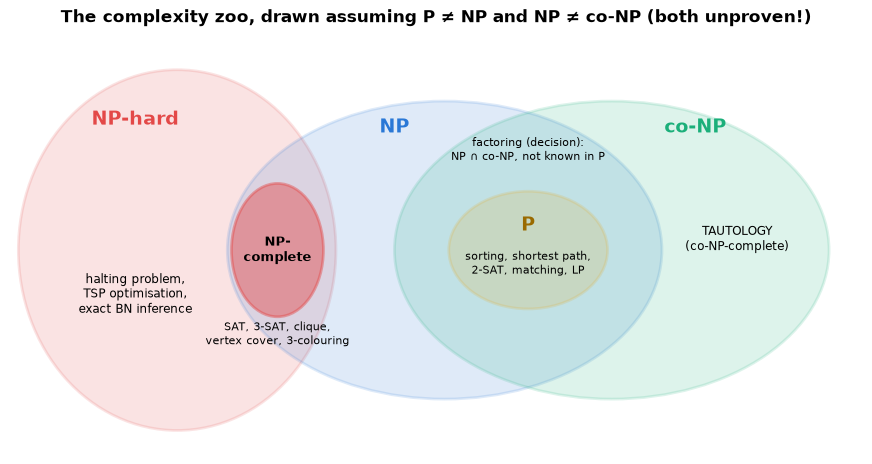

In [3]:
from matplotlib.patches import Ellipse

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.set_xlim(-0.6, 9.6); ax.set_ylim(0.4, 5.8); ax.axis("off"); ax.grid(False)
regions = [  # (centre x, centre y, width, height, colour)
    (1.4, 3.0, 3.8, 4.6, PALETTE[7]),     # NP-hard (a big region; only its right tip lies inside NP)
    (4.6, 3.0, 5.2, 3.8, PALETTE[0]),     # NP
    (6.6, 3.0, 5.2, 3.8, PALETTE[2]),     # co-NP
    (5.6, 3.0, 1.9, 1.5, PALETTE[3]),     # P (inside NP ∩ co-NP)
]
for x, y, w, h, c in regions:
    ax.add_patch(Ellipse((x, y), w, h, facecolor=c, alpha=0.15, edgecolor=c, lw=2))
ax.add_patch(Ellipse((2.6, 3.0), 1.1, 1.7, facecolor=PALETTE[7], alpha=0.45, edgecolor=PALETTE[7], lw=2))
ax.text(0.9, 4.6, "NP-hard", fontsize=14, weight="bold", color=PALETTE[7], ha="center")
ax.text(0.9, 2.2, "halting problem,\nTSP optimisation,\nexact BN inference", fontsize=8.5, ha="center")
ax.text(2.6, 3.0, "NP-\ncomplete", fontsize=9, weight="bold", ha="center", va="center")
ax.text(2.6, 1.8, "SAT, 3-SAT, clique,\nvertex cover, 3-colouring", fontsize=8, ha="center")
ax.text(4.0, 4.5, "NP", fontsize=14, weight="bold", color=PALETTE[0], ha="center")
ax.text(7.6, 4.5, "co-NP", fontsize=14, weight="bold", color=PALETTE[2], ha="center")
ax.text(5.6, 3.25, "P", fontsize=14, weight="bold", color="#9a6a00", ha="center")
ax.text(5.6, 2.7, "sorting, shortest path,\n2-SAT, matching, LP", fontsize=8, ha="center")
ax.text(8.1, 3.0, "TAUTOLOGY\n(co-NP-complete)", fontsize=8.5, ha="center")
ax.text(5.6, 4.15, "factoring (decision):\nNP ∩ co-NP, not known in P", fontsize=8, ha="center")
ax.set_title("The complexity zoo, drawn assuming P ≠ NP and NP ≠ co-NP (both unproven!)")
plt.show()

**What just happened?** The diagram is the standard picture *if* P ≠ NP (and NP ≠ co-NP): P sits inside NP ∩ co-NP; the NP-complete problems are exactly the overlap of NP and NP-hard; the rest of the NP-hard region lies outside NP. If P = NP, the whole NP and co-NP region collapses into P (and the NP-complete set would equal P, minus two trivial languages).

> ⚠️ **Common mistake:** "NP means not polynomial". No. NP means *nondeterministic polynomial*: yes-answers can be **checked** quickly. Every problem in P is also in NP.

> ⚠️ **Common mistake: the direction of a reduction.** To prove X is hard, reduce a **known hard** problem **to X** (hard ≤ₚ X). Reducing X to SAT only shows X is *no harder* than SAT, which proves nothing about hardness.

---
## 3. Polynomial-time verifiers

> 💬 **In plain English:** for an NP problem, a proposed answer can be checked in a single quick pass.

**Intuition.** A Sudoku is hard to solve but easy to check: you just look at every row, column and box. NP is exactly the class of problems with this "easy to check" property.

**Definition.** A **verifier** for L is a polynomial-time algorithm V(x, c) such that x ∈ L ⇔ there is a certificate c with |c| ≤ poly(|x|) and V(x, c) = true.

| Problem | Instance | Certificate | Check | Time |
|---|---|---|---|---|
| SAT | CNF formula | an assignment | every clause has a true literal | O(total literals) |
| Hamiltonian cycle | graph | a vertex ordering | it is a permutation and consecutive vertices are adjacent | O(n) with an adjacency set |
| Subset sum | numbers, target T | a set of indices | the chosen numbers add up to T | O(n) additions |

We represent CNF formulas as in the DIMACS format used by real SAT solvers: variables are 1, 2, …, n, the literal −3 means "NOT x₃", and a clause is a list of literals.

In [4]:
def verify_sat(cnf, assignment):
    """assignment: dict var -> bool. True iff every clause has at least one true literal."""
    return all(any(assignment[abs(l)] == (l > 0) for l in clause) for clause in cnf)

def verify_ham_cycle(G, order):
    n = G.number_of_nodes()
    if len(order) != n or set(order) != set(G.nodes()):
        return False                                     # must visit every vertex exactly once
    return all(G.has_edge(order[i], order[(i + 1) % n]) for i in range(n))   # and close the loop

def verify_subset_sum(nums, target, idx):
    return len(set(idx)) == len(idx) and all(0 <= i < len(nums) for i in idx) \
        and sum(nums[i] for i in idx) == target

# (x1 ∨ ¬x2) ∧ (x2 ∨ x3) ∧ (¬x1 ∨ ¬x3)
cnf = [[1, -2], [2, 3], [-1, -3]]
print("SAT certificate {x1:T, x2:T, x3:F} valid?", verify_sat(cnf, {1: True, 2: True, 3: False}))
print("SAT certificate {x1:T, x2:F, x3:T} valid?", verify_sat(cnf, {1: True, 2: False, 3: True}))
D = nx.dodecahedral_graph()                              # Hamilton's 1857 "Icosian game" graph
bad_order = list(range(20)); random.Random(0).shuffle(bad_order)
print("Ham-cycle certificate (a random vertex order) valid?", verify_ham_cycle(D, bad_order))
# find a real Hamiltonian cycle by brute-force DFS, then verify it
def find_ham_cycle(G):
    n, start = G.number_of_nodes(), next(iter(G.nodes()))
    path, seen = [start], {start}
    def dfs():
        if len(path) == n:
            return G.has_edge(path[-1], start)
        for v in G.neighbors(path[-1]):
            if v not in seen:
                path.append(v); seen.add(v)
                if dfs(): return True
                path.pop(); seen.discard(v)
        return False
    return path if dfs() else None
ham = find_ham_cycle(D)
print("Ham cycle found by search:", ham, "-> verifier says", verify_ham_cycle(D, ham))
nums = [3, 34, 4, 12, 5, 2]
print("subset sum: indices [2, 4] sum to 9?", verify_subset_sum(nums, 9, [2, 4]))

SAT certificate {x1:T, x2:T, x3:F} valid? True
SAT certificate {x1:T, x2:F, x3:T} valid? False
Ham-cycle certificate (a random vertex order) valid? False
Ham cycle found by search: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19] -> verifier says True
subset sum: indices [2, 4] sum to 9? True


 n  subsets tried search (s) verify (s)
 8            256     0.0004   0.000016
10           1024     0.0083   0.000018
12           4096     0.0219   0.000017
14          16384     0.0885   0.000017
16          65536     0.4233   0.000017
18         262144     1.4050   0.000018


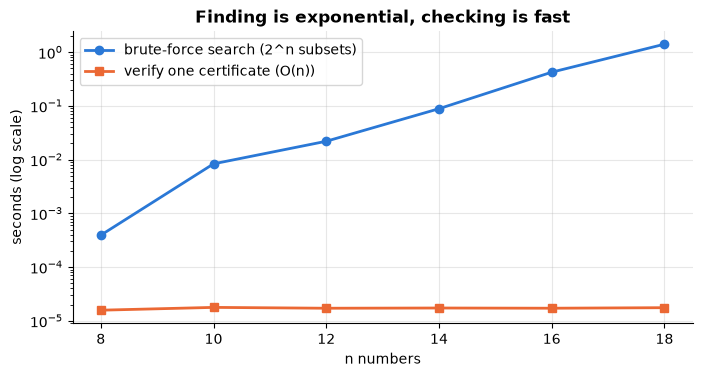

In [5]:
# Finding vs checking: brute-force subset sum is 2^n, verification is n
def brute_subset_sum(nums, target):
    for r in range(len(nums) + 1):
        for idx in itertools.combinations(range(len(nums)), r):
            if sum(nums[i] for i in idx) == target:
                return list(idx)
    return None

rows = []
rng = random.Random(1)
for n in range(8, 19, 2):
    nums = [rng.randint(1, 10**6) for _ in range(n)]
    target = sum(nums) + 1                               # impossible target: forces a full search
    t0 = time.perf_counter(); res = brute_subset_sum(nums, target); t_find = time.perf_counter() - t0
    cert = list(range(n // 2))
    t0 = time.perf_counter(); verify_subset_sum(nums, sum(nums[i] for i in cert), cert); t_check = time.perf_counter() - t0
    rows.append({"n": n, "subsets tried": 2**n, "search (s)": t_find, "verify (s)": t_check})
    assert res is None
df = pd.DataFrame(rows)
print(df.to_string(index=False, formatters={"search (s)": "{:.4f}".format, "verify (s)": "{:.6f}".format}))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.semilogy(df.n, df["search (s)"], "o-", label="brute-force search (2^n subsets)")
ax.semilogy(df.n, df["verify (s)"], "s-", label="verify one certificate (O(n))")
ax.set(xlabel="n numbers", ylabel="seconds (log scale)", title="Finding is exponential, checking is fast"); ax.legend()
plt.show()

**What just happened?** The verifiers check certificates by simply walking through them. The search for a Hamiltonian cycle needed a backtracking DFS, but checking the returned cycle took one pass. For subset sum, every +2 in n multiplies the brute-force time by about 4 (a straight line on the log scale), while verification stays at microseconds. **That gap is the essence of NP.**

---
## 4. SAT: brute force and DPLL

> 💬 **In plain English:** SAT asks whether some true/false setting makes a logic formula true; DPLL is the clever search that real solvers build on.

**SAT** (Boolean satisfiability): given a propositional formula in **conjunctive normal form** (an AND of clauses, each an OR of literals), is there an assignment that makes it true? **3-SAT** restricts every clause to exactly 3 literals. Both are NP-complete. In contrast, **2-SAT** is in P (linear time, via strongly connected components; see practice problem 5).

**Brute force** tries all 2ⁿ assignments: Θ(2ⁿ · m) time for m clauses.

**DPLL** (Davis–Putnam–Logemann–Loveland, 1962) is backtracking search plus two simplification rules:
1. **Unit propagation:** a clause with one literal left forces that literal to be true. Apply this repeatedly.
2. **Pure literal elimination:** if a variable appears with only one sign, set it to satisfy all those clauses.
3. **Branch:** pick a literal (here: the most frequent one), try it true, and if that fails, try it false.

When a literal ℓ is set true, every clause containing ℓ is satisfied (removed), and ¬ℓ is deleted from the remaining clauses. An **empty clause** means a conflict, so we backtrack.

Worked example: F = (x₁ ∨ x₂) ∧ (¬x₁ ∨ x₂) ∧ (¬x₂ ∨ x₃) ∧ (¬x₃ ∨ ¬x₁)
```
no unit clauses; no pure literals (x1 and x2 and x3 all appear with both signs)
branch x2 = True  → clauses with x2 vanish; (¬x2 ∨ x3) becomes the unit (x3)
   unit x3 = True  → (¬x3 ∨ ¬x1) becomes the unit (¬x1)
   unit x1 = False → no clauses left: SAT with x1=F, x2=T, x3=T
```
The worst case is still exponential, but propagation prunes huge parts of the search tree. Modern **CDCL** solvers (MiniSat, CaDiCaL, Kissat) add conflict-driven clause learning, non-chronological backjumping, restarts and clever data structures (watched literals), and routinely solve industrial instances with millions of variables.

In [6]:
def brute_force_sat(cnf, n):
    for bits in itertools.product([False, True], repeat=n):
        a = {i + 1: bits[i] for i in range(n)}
        if verify_sat(cnf, a):
            return a
    return None

def simplify(clauses, lit):
    """Set literal `lit` true: drop satisfied clauses, delete ¬lit elsewhere. None = conflict."""
    out = []
    for c in clauses:
        if lit in c:
            continue                                    # clause satisfied
        if -lit in c:
            c = [x for x in c if x != -lit]             # that literal is now false
            if not c:
                return None                             # empty clause: conflict
        out.append(c)
    return out

def dpll(clauses, assignment=None, stats=None):
    """Return a satisfying (partial) assignment dict, or None if unsatisfiable."""
    assignment = dict(assignment or {})
    if stats is not None:
        stats["calls"] += 1
    while True:                                         # 1. unit propagation
        unit = next((c[0] for c in clauses if len(c) == 1), None)
        if unit is None:
            break
        assignment[abs(unit)] = unit > 0
        clauses = simplify(clauses, unit)
        if clauses is None:
            return None
    lits = {l for c in clauses for l in c}              # 2. pure literals
    for l in [l for l in lits if -l not in lits]:
        assignment[abs(l)] = l > 0
        clauses = simplify(clauses, l)
    if not clauses:
        return assignment                               # every clause satisfied
    counts = Counter(l for c in clauses for l in c)     # 3. branch on the most frequent literal
    lit = counts.most_common(1)[0][0]
    for choice in (lit, -lit):
        reduced = simplify(clauses, choice)
        if reduced is not None:
            result = dpll(reduced, {**assignment, abs(choice): choice > 0}, stats)
            if result is not None:
                return result
    return None

def complete(assignment, n):
    """Variables that DPLL never had to set can take any value."""
    return {v: assignment.get(v, False) for v in range(1, n + 1)}

def random_3sat(n, m, rng):
    """m clauses, each with 3 distinct variables and random signs."""
    return [[v if rng.random() < 0.5 else -v for v in rng.sample(range(1, n + 1), 3)] for _ in range(m)]

F = [[1, 2], [-1, 2], [-2, 3], [-3, -1]]
print("worked example:", complete(dpll(F), 3))

# Differential test: DPLL vs brute force on 300 small random instances (some SAT, some UNSAT)
rng = random.Random(0)
sat_count = 0
for _ in range(300):
    n = rng.randint(3, 10); m = rng.randint(1, 7 * n)
    cnf = random_3sat(n, m, rng)
    bf, dp = brute_force_sat(cnf, n), dpll(cnf)
    assert (bf is None) == (dp is None)                 # same yes/no answer
    if dp is not None:
        assert verify_sat(cnf, complete(dp, n))         # and DPLL's assignment really works
        sat_count += 1
print(f"DPLL agrees with brute force on 300 random instances ({sat_count} SAT, {300 - sat_count} UNSAT)")

worked example: {1: False, 2: True, 3: True}


DPLL agrees with brute force on 300 random instances (232 SAT, 68 UNSAT)


In [7]:
rows = []
rng = random.Random(4)
for n in [8, 10, 12, 14]:
    tb, td, calls = [], [], []
    for _ in range(5):
        cnf = random_3sat(n, round(4.26 * n), rng)
        t0 = time.perf_counter(); brute_force_sat(cnf, n); tb.append(time.perf_counter() - t0)
        st = {"calls": 0}
        t0 = time.perf_counter(); dpll(cnf, stats=st); td.append(time.perf_counter() - t0); calls.append(st["calls"])
    rows.append({"n": n, "brute force (ms)": 1000 * np.mean(tb), "DPLL (ms)": 1000 * np.mean(td),
                 "DPLL calls (mean)": np.mean(calls), "2^n": 2**n})
print(pd.DataFrame(rows).round(2).to_string(index=False))

 n  brute force (ms)  DPLL (ms)  DPLL calls (mean)   2^n
 8              5.04       0.35                5.2   256
10             18.85       1.99                7.6  1024
12            117.32       3.81                8.8  4096
14            248.29       2.28                9.6 16384


**What just happened?** DPLL gave the same SAT/UNSAT answer as brute force on all 300 test formulas, and every assignment it returned passed the verifier. On hard random instances (ratio 4.26, see next section) brute force grows like 2ⁿ, while DPLL explores only a handful of search-tree nodes at these sizes, thanks to unit propagation and pure literals. (DPLL is still exponential in the worst case; it just has a much smaller base on typical inputs.)

**Complexity:** brute force Θ(2ⁿ·m); DPLL O(2ⁿ·m) worst case. Space: O(n·m) for the copies of the clause list along one branch of the recursion.

---
## 5. Random 3-SAT and the phase transition

> 💬 **In plain English:** random SAT puzzles are easy when they have few or very many rules, and hardest right at the tipping point.

Generate random 3-SAT formulas with n variables and m clauses, and vary the **ratio r = m/n**:
- with few clauses (small r) the formula is almost always satisfiable, and easy;
- with many clauses (large r) it is almost always unsatisfiable, and contradictions are found quickly;
- around **r ≈ 4.26** the probability of satisfiability drops sharply from ≈ 1 to ≈ 0, and this is exactly where DPLL works hardest (Mitchell, Selman & Levesque 1992; Kirkpatrick & Selman 1994).

As n grows, the drop gets sharper. Its location for 3-SAT was proved rigorously only for large k-SAT (Ding, Sly & Sun, 2015). For 3-SAT the threshold ≈ 4.267 comes from statistical-physics predictions that match experiments.

440 formulas solved in 6.3 s
      P(SAT)       median DPLL calls      
n         20    35                20    35
ratio                                     
2.0     1.00  1.00               6.0   7.0
2.5     1.00  1.00               7.0  10.0
3.0     1.00  1.00               7.5  10.0
3.5     1.00  1.00               7.0  12.0
4.0     0.95  0.80               7.5  21.0
4.5     0.55  0.15              13.5  58.0
5.0     0.30  0.20              14.5  43.0
5.5     0.00  0.00              19.0  40.0
6.0     0.10  0.00              16.0  38.0
6.5     0.00  0.00              15.0  29.0
7.0     0.00  0.00              13.0  25.0


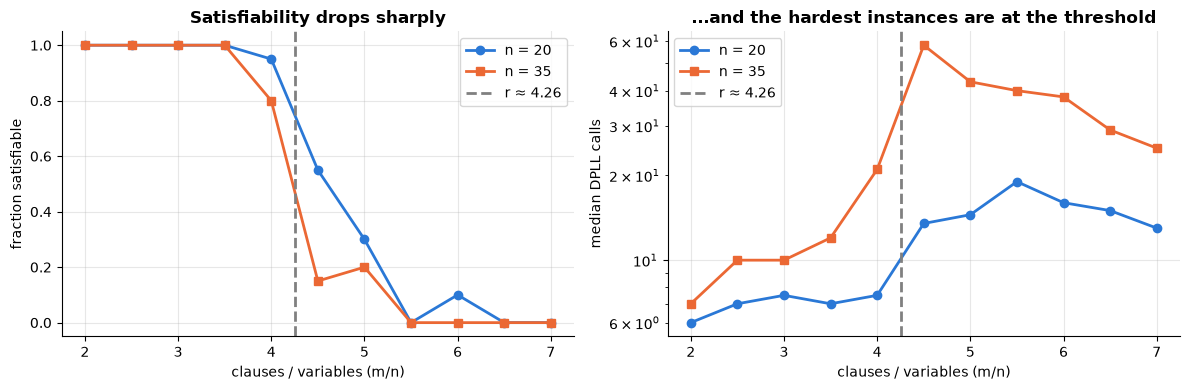

In [8]:
ratios = np.arange(2.0, 7.01, 0.5)
results = []
rng = random.Random(7)
t_start = time.perf_counter()
for n in [20, 35]:
    for r in ratios:
        sat, calls = 0, []
        for _ in range(20):
            st = {"calls": 0}
            res = dpll(random_3sat(n, round(r * n), rng), stats=st)
            sat += res is not None
            calls.append(st["calls"])
        results.append({"n": n, "ratio": r, "P(SAT)": sat / 20, "median DPLL calls": np.median(calls)})
pt = pd.DataFrame(results)
print(f"{len(results) * 20} formulas solved in {time.perf_counter() - t_start:.1f} s")
print(pt.pivot(index="ratio", columns="n", values=["P(SAT)", "median DPLL calls"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for n, mk in [(20, "o-"), (35, "s-")]:
    d = pt[pt.n == n]
    axes[0].plot(d.ratio, d["P(SAT)"], mk, label=f"n = {n}")
    axes[1].plot(d.ratio, d["median DPLL calls"], mk, label=f"n = {n}")
for ax in axes:
    ax.axvline(4.26, color="gray", ls="--", label="r ≈ 4.26")
    ax.set_xlabel("clauses / variables (m/n)"); ax.legend()
axes[0].set(ylabel="fraction satisfiable", title="Satisfiability drops sharply")
axes[1].set(ylabel="median DPLL calls", title="...and the hardest instances are at the threshold", yscale="log")
plt.tight_layout(); plt.show()

**What just happened?** Read the two panels together. For both sizes, the fraction of satisfiable formulas falls from 1 to 0 between r ≈ 4 and 5.5, more steeply for n = 35 than for n = 20. For n = 35 the median search effort peaks right at the threshold (r ≈ 4.5 here) and is several times higher than for n = 20, whose curve is flatter because all its instances are tiny: the hardest random formulas live at the threshold, and their difficulty grows exponentially with n. This is why SAT-solver benchmarks use r ≈ 4.26, and why "random" does not mean "easy". (With only 20 formulas per point the curves are a bit noisy; the trend is what matters.)

> 🎓 **Exam / interview tip:** a phase transition is evidence about *typical-case* hardness of a distribution. It is not a statement about worst-case complexity, which is what NP-completeness is about.

---
## 6. Reductions as code

> 💬 **In plain English:** a reduction is a translator: it rewrites one problem as another, so a solver for the second solves the first.

A reduction is a **compiler** from instances of problem A to instances of problem B that preserves the yes/no answer. We will implement the classic chain and test each step.

### 6a. 3-SAT ≤ₚ Independent Set

An **independent set** is a set of vertices with no edge between any two of them. INDEPENDENT-SET: does G have an independent set of size ≥ k?

**Construction (Karp 1972, CLRS §34.5).** For a 3-CNF formula with m clauses:
- for each clause, add a **triangle** of 3 vertices, one per literal (so at most one vertex per clause can be picked);
- add a **conflict edge** between every pair of vertices labelled x and ¬x (so we never pick contradictory literals);
- set k = m.

**Correctness.** (⇒) A satisfying assignment makes at least one literal per clause true; pick one such vertex per triangle. No two picks conflict, because they are all true literals. That gives an independent set of size m. (⇐) An independent set of size m has exactly one vertex per triangle and no conflicting pair; set those literals to true (other variables arbitrary). Then every clause is satisfied. The graph has 3m vertices and O(m²) edges, so the reduction runs in polynomial time.

```
(x1 ∨ x2 ∨ ¬x3) ∧ (¬x1 ∨ x2 ∨ x3)

   x1 ──── x2          ¬x1 ──── x2         conflict edges (dashed in the plot):
     \    /              \     /             x1 — ¬x1,   ¬x3 — x3
      ¬x3                  x3
```

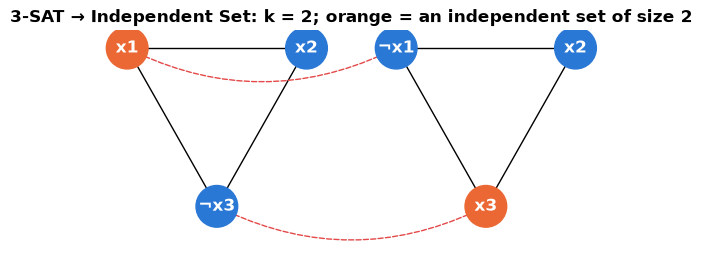

assignment read back from the independent set: {1: True, 2: False, 3: True}


In [9]:
def sat_to_independent_set(cnf):
    """Return (graph, k). Vertex (i, j) is literal j of clause i."""
    G = nx.Graph()
    for i, clause in enumerate(cnf):
        nodes = [(i, j) for j in range(len(clause))]
        for v in nodes:
            G.add_node(v, literal=clause[v[1]])
        G.add_edges_from(itertools.combinations(nodes, 2))          # clause triangle
    for u, v in itertools.combinations(list(G.nodes()), 2):
        if G.nodes[u]["literal"] == -G.nodes[v]["literal"]:
            G.add_edge(u, v, conflict=True)                          # x and ¬x can't both be chosen
    return G, len(cnf)

def assignment_from_independent_set(G, S, n):
    """Map an independent set of size m back to a satisfying assignment."""
    a = {v: False for v in range(1, n + 1)}
    for node in S:
        lit = G.nodes[node]["literal"]
        a[abs(lit)] = lit > 0
    return a

def max_independent_set(G):
    """Exact maximum independent set using networkx's exact max clique on the complement graph."""
    clique, _ = nx.max_weight_clique(nx.complement(G), weight=None)
    return set(clique)

example = [[1, 2, -3], [-1, 2, 3]]
Gx, k = sat_to_independent_set(example)
pos = {(i, j): (3 * i + [0, 2, 1][j], [1, 1, 0][j]) for i in range(2) for j in range(3)}
fig, ax = plt.subplots(figsize=(7, 2.8)); ax.axis("off"); ax.grid(False)
solid = [(u, v) for u, v, d in Gx.edges(data=True) if not d.get("conflict")]
dashed = [(u, v) for u, v, d in Gx.edges(data=True) if d.get("conflict")]
S = max_independent_set(Gx)
nx.draw_networkx_nodes(Gx, pos, node_color=[PALETTE[1] if v in S else PALETTE[0] for v in Gx], node_size=900, ax=ax)
nx.draw_networkx_edges(Gx, pos, edgelist=solid, ax=ax)
nx.draw_networkx_edges(Gx, pos, edgelist=dashed, style="dashed", edge_color=PALETTE[7], ax=ax, connectionstyle="arc3,rad=0.25", arrows=True, arrowstyle="-")
lab = {v: ("¬" if d["literal"] < 0 else "") + f"x{abs(d['literal'])}" for v, d in Gx.nodes(data=True)}
nx.draw_networkx_labels(Gx, pos, lab, font_color="white", font_weight="bold", ax=ax)
ax.set_title(f"3-SAT → Independent Set: k = {k}; orange = an independent set of size {len(S)}")
plt.show()
print("assignment read back from the independent set:", assignment_from_independent_set(Gx, S, 3))

In [10]:
# Test: the reduction preserves answers on random formulas, including forced-UNSAT ones
rng = random.Random(3)
checked = Counter()
for t in range(90):
    n = rng.randint(3, 5)
    cnf = random_3sat(n, rng.randint(2, 6), rng)
    if t % 3 == 0:                                   # force UNSAT: all 8 sign patterns on x1, x2, x3
        cnf += [[s1 * 1, s2 * 2, s3 * 3] for s1 in (1, -1) for s2 in (1, -1) for s3 in (1, -1)]
    satisfiable = brute_force_sat(cnf, n) is not None
    G_is, k = sat_to_independent_set(cnf)
    S = max_independent_set(G_is)
    assert (len(S) >= k) == satisfiable              # yes ⇔ yes
    if satisfiable:
        assert verify_sat(cnf, assignment_from_independent_set(G_is, S, n))   # certificate maps back
    checked[satisfiable] += 1
print(f"3-SAT → IS preserved the answer on 90 formulas: {checked[True]} SAT, {checked[False]} UNSAT")

3-SAT → IS preserved the answer on 90 formulas: 60 SAT, 30 UNSAT


**What just happened?** For every formula, "satisfiable" and "the graph has an independent set of size m" gave the same answer, and every independent set translated back into a valid satisfying assignment. A third of the formulas were forced to be unsatisfiable (they contain all 8 sign combinations on x₁, x₂, x₃), so both answers were tested. We used networkx's exact clique solver as an *independent* check, so we did not have to trust our own code twice.

### 6b. Independent Set ≤ₚ Vertex Cover ≤ₚ Clique

Two beautiful one-line reductions:
- **S is an independent set ⇔ V ∖ S is a vertex cover.** If no edge has both ends in S, every edge has at least one end outside S. So G has an independent set of size ≥ k ⇔ G has a vertex cover of size ≤ n − k.
- **S is an independent set in G ⇔ S is a clique in the complement graph Ḡ** (Ḡ has an edge exactly where G does not). So the instance (G, k) maps to (Ḡ, k).

Chaining them gives 3-SAT ≤ₚ IS ≤ₚ VC and IS ≤ₚ CLIQUE, so all of these are NP-complete (each is in NP: the set itself is the certificate).

In [11]:
def is_to_vc(G, k):      return G, G.number_of_nodes() - k       # (G, k) → (G, n − k)
def is_to_clique(G, k):  return nx.complement(G), k              # (G, k) → (Ḡ, k)

def brute_max_is(G):
    nodes = list(G.nodes())
    for r in range(len(nodes), -1, -1):
        for S in itertools.combinations(nodes, r):
            if not any(G.has_edge(u, v) for u, v in itertools.combinations(S, 2)):
                return r

def brute_min_vc(G):
    nodes = list(G.nodes())
    for r in range(len(nodes) + 1):
        for S in itertools.combinations(nodes, r):
            S = set(S)
            if all(u in S or v in S for u, v in G.edges()):
                return r

def brute_max_clique(G):
    return max((len(c) for c in nx.find_cliques(G)), default=0) if G.number_of_nodes() else 0

rng = random.Random(8)
for _ in range(100):
    n = rng.randint(1, 11)
    G = nx.gnp_random_graph(n, rng.random(), seed=rng.randrange(10**6))
    a = brute_max_is(G)
    for k in range(n + 1):
        has_is = a >= k
        Gv, kv = is_to_vc(G, k)
        Gc, kc = is_to_clique(G, k)
        assert has_is == (brute_min_vc(Gv) <= kv) == (brute_max_clique(Gc) >= kc)
print("IS → VC and IS → Clique preserved the answer for every k on 100 random graphs")

IS → VC and IS → Clique preserved the answer for every k on 100 random graphs


**What just happened?** On 100 random graphs and for every possible k, the three questions "independent set ≥ k?", "vertex cover ≤ n − k?" and "clique ≥ k in the complement?" always had the same answer. The reductions are just a subtraction and a graph complement, both polynomial (O(1) and O(n²)).

> 🎓 **Exam / interview tip:** when you write a reduction proof, always state four things: (1) the construction, (2) that it runs in polynomial time, (3) yes-instance ⇒ yes-instance, (4) yes-instance ⇐ yes-instance (usually proved as "if the new instance is yes, then so is the original"). Forgetting (4) is the most common way to lose marks.

---
## 7. Cook–Levin and a catalogue of NP-complete problems

> 💬 **In plain English:** SAT was the first problem proved NP-complete; thousands of others followed by reductions.

**Cook–Levin theorem (Cook 1971, Levin 1973): SAT is NP-complete.** We need the first NP-complete problem "from scratch", by reducing *every* NP problem to SAT. Proof idea:
- A problem in NP has a verifier that runs for at most p(n) steps. Picture its whole computation as a **tableau**: a p(n) × p(n) grid whose row t is the machine's tape, head position and state at time t.
- Introduce Boolean variables "cell (t, i) holds symbol s". Write clauses that say: the first row is the input together with *some* certificate (left free); each 2×3 window follows the machine's transition rules (a local check!); some row is in the accepting state.
- The formula has polynomial size, and it is satisfiable ⇔ some certificate makes the verifier accept ⇔ the input is a yes-instance.

After that, everything else follows by chains of reductions. Karp (1972) showed 21 problems NP-complete this way. Garey & Johnson (1979) catalogued hundreds.

| NP-complete problem | Similar-looking problem in P |
|---|---|
| 3-SAT | 2-SAT (implication graph + SCC, linear time) |
| 3-colouring | 2-colouring (= bipartiteness, BFS) |
| Hamiltonian cycle (visit every **vertex** once) | Euler circuit (use every **edge** once: all degrees even + connected) |
| longest simple path | shortest path (Dijkstra / Bellman–Ford) |
| max cut | min cut (max-flow, see notebook 04) |
| 3-dimensional matching | bipartite (2-D) matching (notebook 04) |
| integer linear programming (feasibility) | linear programming (ellipsoid / interior point methods) |
| subset sum, partition, 0/1 knapsack (decision) | fractional knapsack (greedy) |
| set cover, vertex cover | edge cover; vertex cover in bipartite graphs (König's theorem + matching) |
| clique, independent set (general graphs) | the same problems on interval or bipartite graphs |
| bin packing, graph colouring, TSP (decision), Steiner tree | minimum spanning tree |
| generalised Sudoku (n² × n²), Minesweeper consistency | checking a filled Sudoku |

> ⚠️ **Common mistake:** "NP-hard means it can never be solved in practice". Many NP-hard problems are routinely solved exactly at real sizes (SAT solvers, ILP solvers, TSP with Concorde on tens of thousands of cities). NP-hardness is about the worst case as n → ∞.

---
## 8. Pseudo-polynomial algorithms: why knapsack DP is not polynomial

> 💬 **In plain English:** an algorithm that is fast only when the numbers are small is not truly fast, because big numbers take few digits to write.

The 0/1 knapsack DP from [`dsa/09`](../dsa/09_dynamic_programming.ipynb) runs in **O(n·W)** time. That *looks* polynomial, but "polynomial" is measured in the **length of the input in bits**. The capacity W is written with only about log₂ W bits, so

$$O(n W) = O(n \cdot 2^{\log_2 W}) = O(n \cdot 2^{\text{bits of } W}),$$

which is **exponential in the input size**. An algorithm that is polynomial in the *numeric values* (rather than their bit lengths) is called **pseudo-polynomial**. A problem that stays NP-hard even when all numbers are bounded by a polynomial in n (e.g. 3-partition, bin packing, TSP) is **strongly NP-hard**; knapsack and subset sum are only **weakly NP-hard** (Garey & Johnson 1979, §4.2).

Experiment: n = 30 items; each extra bit in the numbers doubles W. Watch the DP time double too.

knapsack DP matches brute force on 200 random instances


 bits per number       W  input size (bits)  DP cells n·W seconds
              12    4096                561        122880  0.0005
              14   16384                606        491520  0.0027
              16   65536                664       1966080  0.0123
              18  262144                741       7864320  0.0969
              20 1048576                815      31457280  0.4769
              22 4194304                877     125829120  1.7608


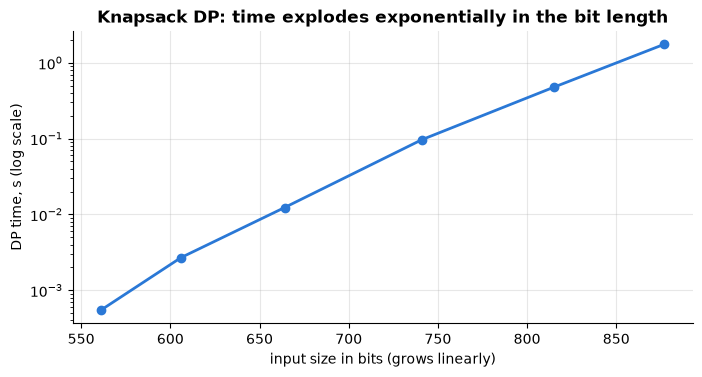

In [12]:
def knapsack_dp(weights, values, W):
    """0/1 knapsack, O(n W) time, O(W) space. dp[c] = best value with capacity c.
    Vectorised with NumPy over capacities; still n*W cell updates."""
    dp = np.zeros(W + 1, dtype=np.int64)
    for w, v in zip(weights, values):
        if w <= W:
            # iterate capacities "downwards" in one shot: new[c] = max(dp[c], dp[c - w] + v)
            dp[w:] = np.maximum(dp[w:], dp[:W + 1 - w] + v)
    return int(dp[W])

def knapsack_brute(weights, values, W):
    best = 0
    for r in range(len(weights) + 1):
        for idx in itertools.combinations(range(len(weights)), r):
            if sum(weights[i] for i in idx) <= W:
                best = max(best, sum(values[i] for i in idx))
    return best

rng = random.Random(5)
for _ in range(200):                                       # correctness check on small instances
    n = rng.randint(1, 10)
    w = [rng.randint(1, 30) for _ in range(n)]; v = [rng.randint(1, 50) for _ in range(n)]
    W = rng.randint(0, 100)
    assert knapsack_dp(w, v, W) == knapsack_brute(w, v, W)
print("knapsack DP matches brute force on 200 random instances")

rows = []
n_items = 30
for bits in range(12, 23, 2):
    W = 2**bits
    w = [rng.randint(1, W // 4) for _ in range(n_items)]   # weights scale with W
    v = [rng.randint(1, 1000) for _ in range(n_items)]
    t0 = time.perf_counter(); best = knapsack_dp(w, v, W); dt = time.perf_counter() - t0
    input_bits = sum(x.bit_length() for x in w + v) + W.bit_length()
    rows.append({"bits per number": bits, "W": W, "input size (bits)": input_bits,
                 "DP cells n·W": n_items * W, "seconds": dt})
kd = pd.DataFrame(rows)
print(kd.to_string(index=False, formatters={"seconds": "{:.4f}".format}))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.semilogy(kd["input size (bits)"], kd["seconds"], "o-")
ax.set(xlabel="input size in bits (grows linearly)", ylabel="DP time, s (log scale)",
       title="Knapsack DP: time explodes exponentially in the bit length")
plt.show()

**What just happened?** Each row adds 2 bits to every number, so the *input size* grows by only about 50–80 bits per row (a small linear increase), but W and the number of DP cells grow exactly **4× per row**, and the running time follows (roughly 3–4× per row once the arrays are large; small timings are noisy). On a log scale, time against input size is roughly a straight line: exponential growth. (For the smallest rows the NumPy overhead dominates, so the first steps are flatter.) With 64-bit weights the table would need 2⁶⁴ cells. By contrast, if the numbers were written in **unary** (W written as W symbols), the same algorithm would be polynomial in that input length.

---
## 9. Coping with NP-hardness

> 💬 **In plain English:** hard problems are still solved every day by giving up perfection, speed guarantees or generality.

Being NP-hard does not mean giving up. It means choosing which guarantee to drop.

| Strategy | What you give up | Examples | Where in this repo |
|---|---|---|---|
| **Exact exponential, but smart** (backtracking, branch and bound, DP over subsets, meet in the middle) | polynomial time (the worst case is still exponential) | DPLL/CDCL, Held–Karp TSP in O(n²2ⁿ), N-Queens backtracking | this notebook; [`dsa/09`](../dsa/09_dynamic_programming.ipynb) (bitmask TSP) |
| **Approximation algorithms** | optimality, but with a *proven* ratio | vertex cover 2-approx, greedy set cover (ln n), Christofides (1.5 for metric TSP), knapsack FPTAS | [03 · Approximation](03_approximation_and_parameterized_algorithms.ipynb) |
| **Parameterized (FPT) algorithms** | polynomial time in *all* parameters; exponential only in a small k | vertex cover in O(2ᵏ·n) | [03 · Approximation](03_approximation_and_parameterized_algorithms.ipynb) |
| **Heuristics and metaheuristics** | any guarantee | hill climbing, simulated annealing, genetic algorithms, tabu search, 2-opt | [`classical_ai/04`](../classical_ai/04_local_search_and_optimization.ipynb) |
| **Special structure** | generality | 2-SAT, trees (DP on trees), bipartite or planar graphs, bounded treewidth | [`dsa/09`](../dsa/09_dynamic_programming.ipynb) (DP on trees) |
| **Off-the-shelf solvers** | control (but decades of engineering) | SAT (Kissat, CaDiCaL), SMT (Z3), MILP (HiGHS, Gurobi, CP-SAT), CP | the next batch of notebooks covers LP/ILP |
| **Randomization** | certainty (Monte Carlo) or a fixed running time (Las Vegas) | random restarts, WalkSAT, Karger | [01 · Amortized and randomized](01_amortized_and_randomized_algorithms.ipynb) |

---
## 10. 🔗 How this connects to modern AI

> 💬 **In plain English:** many core AI tasks are NP-hard, which is why AI uses greedy methods, approximations and gradient descent.

Many problems at the heart of AI and ML are NP-hard, which explains *why* the field relies so much on approximation, greedy methods, gradient descent and heuristics:

| AI problem | Hardness result | What practitioners do instead |
|---|---|---|
| exact inference in Bayesian networks | NP-hard (Cooper 1990); even approximating it to a fixed accuracy is NP-hard (Dagum & Luby 1993) | variable elimination on low-treewidth graphs, sampling (MCMC), variational inference; see [`classical_ai/09`](../classical_ai/09_uncertain_knowledge_and_reasoning.ipynb) |
| learning the smallest / optimal decision tree | NP-complete (Hyafil & Rivest 1976) | greedy splitting by information gain or Gini (ID3, CART) |
| best subset feature selection | NP-hard (Natarajan 1995, sparse approximation) | greedy forward/backward selection, L1 regularisation (lasso) |
| training a tiny 3-node neural network to fit data exactly | NP-complete (Blum & Rivest 1992) | stochastic gradient descent, which works well in practice |
| classical planning (STRIPS) | PSPACE-complete (Bylander 1994), even harder than NP | heuristic search (A* with relaxed-plan heuristics), SAT-based planning |
| k-means clustering (optimal) | NP-hard, even for k = 2 (Aloise et al. 2009) | Lloyd's algorithm with k-means++ seeding |
| constraint satisfaction, scheduling, timetabling | NP-complete in general | CSP solvers, CP-SAT, local search |

LLM systems also use NP-hard machinery as **tools**: an LLM agent can translate a puzzle or a scheduling request into SAT/SMT or ILP constraints and call a solver such as Z3 or OR-Tools, rather than "reasoning" through an exponential search in text.

**Demo: feature-subset selection.** Choosing the best k of d features means searching C(d, k) subsets, 2ᵈ in total. With the 10-feature diabetes dataset that is still feasible (1,023 non-empty subsets), so we can compare the true optimum with the greedy forward selection that libraries use.

In [13]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

X, y = load_diabetes(return_X_y=True)
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.3, random_state=0)

def val_r2(cols):
    """Fit least squares (with intercept) on the chosen columns; return validation R^2."""
    A = np.c_[np.ones(len(X_tr)), X_tr[:, cols]]
    coef, *_ = np.linalg.lstsq(A, y_tr, rcond=None)
    pred = np.c_[np.ones(len(X_va)), X_va[:, cols]] @ coef
    return 1 - np.sum((y_va - pred) ** 2) / np.sum((y_va - y_va.mean()) ** 2)

d = X.shape[1]
t0 = time.perf_counter()
best_exhaustive = {k: max(itertools.combinations(range(d), k), key=lambda c: val_r2(list(c))) for k in range(1, d + 1)}
t_exh = time.perf_counter() - t0

greedy, chosen = {}, []
for k in range(1, d + 1):                               # forward selection: add the best next feature
    nxt = max((j for j in range(d) if j not in chosen), key=lambda j: val_r2(chosen + [j]))
    chosen = chosen + [nxt]
    greedy[k] = list(chosen)

rows = [{"k": k, "subsets searched": math.comb(d, k),
         "exhaustive R²": round(val_r2(list(best_exhaustive[k])), 4),
         "greedy R²": round(val_r2(greedy[k]), 4)} for k in range(1, d + 1)]
fs = pd.DataFrame(rows)
print(fs.to_string(index=False))
print(f"exhaustive search: {2**d - 1} subsets in {t_exh:.2f} s; with d = 50 features it would need 2^50 ≈ {2**50:.1e} fits")
print("greedy forward selection: d(d+1)/2 =", d * (d + 1) // 2, "fits")
assert all(fs["exhaustive R²"] >= fs["greedy R²"] - 1e-12)

 k  subsets searched  exhaustive R²  greedy R²
 1                10         0.2313     0.2313
 2                45         0.3175     0.3175
 3               120         0.3633     0.3633
 4               210         0.3773     0.3773
 5               252         0.3946     0.3946
 6               210         0.3955     0.3945
 7               120         0.3981     0.3897
 8                45         0.3990     0.3934
 9                10         0.3965     0.3965
10                 1         0.3929     0.3929
exhaustive search: 1023 subsets in 1.15 s; with d = 50 features it would need 2^50 ≈ 1.1e+15 fits
greedy forward selection: d(d+1)/2 = 55 fits


**What just happened?** Exhaustive search is optimal by definition, and greedy forward selection (55 fits instead of 1,023) matches it at some sizes k and falls slightly short at others. Look at the two R² columns in your output. Exhaustive search is impossible beyond a few dozen features, which is why real pipelines use greedy selection or lasso: an NP-hard problem, solved approximately, in production every day.

---
## Recap
- Complexity classes are defined for **decision problems**; optimisation versions reduce to them by binary search.
- **P**: solvable in polynomial time. **NP**: yes-answers have polynomial-size certificates checkable in polynomial time. **co-NP**: the same for no-answers. P ⊆ NP ∩ co-NP. Whether P = NP is open.
- **A ≤ₚ B** (a polynomial-time, answer-preserving transformation) means B is at least as hard as A. To show X is NP-complete: X ∈ NP, plus a reduction **from** a known NP-complete problem **to** X.
- **SAT** is NP-complete (Cook–Levin). **DPLL** (unit propagation + pure literals + branching) is the backbone of modern CDCL SAT solvers.
- Random 3-SAT has a **phase transition** near m/n ≈ 4.26, where instances flip from SAT to UNSAT and are hardest.
- 3-SAT ≤ₚ Independent Set (triangles + conflict edges), IS ⇔ VC (complement set), IS ⇔ Clique (complement graph).
- Knapsack's O(nW) DP is **pseudo-polynomial**: exponential in the bit length of W. Knapsack is *weakly* NP-hard.
- NP-hardness is a reason to pick a coping strategy (exact-but-smart, approximation, FPT, heuristics, solvers), and it explains why core AI tasks (BN inference, optimal trees, best subsets, planning) are done approximately.

## Practice problems

**1. (Easy, conceptual)** For each problem, say whether it is in P or NP-complete (assuming P ≠ NP): (a) is there a path from s to t of length ≤ k? (b) is there a *simple* path from s to t of length ≥ k? (c) can the graph be coloured with 2 colours? (d) with 3 colours? (e) does the graph have an Euler circuit? (f) a Hamiltonian cycle?

<details><summary>Show solution</summary>

(a) **P** (BFS/Dijkstra). (b) **NP-complete** (longest path; it contains Hamiltonian path as the case k = n − 1). (c) **P** (bipartiteness test by BFS). (d) **NP-complete**. (e) **P** (connected, and all degrees even). (f) **NP-complete**.

</details>

**2. (Easy, conceptual)** Suppose A ≤ₚ B. Which of these follow? (i) B ∈ P ⇒ A ∈ P. (ii) A ∈ P ⇒ B ∈ P. (iii) A NP-hard ⇒ B NP-hard. (iv) B NP-hard ⇒ A NP-hard.

<details><summary>Show solution</summary>

(i) **Yes**: to solve A, compute f(x) (polynomial time, so |f(x)| is polynomial) and run B's algorithm on it. (ii) **No**: an easy problem reduces to everything (e.g. A = "is n even?" reduces to SAT). (iii) **Yes**: every NP problem reduces to A, and A reduces to B; reductions compose, since a polynomial of a polynomial is a polynomial. (iv) **No**, for the same reason as (ii).

</details>

**3. (Easy, coding)** Write a polynomial-time verifier for graph 3-colouring certificates. What is its running time? Why does this prove 3-COLOURING ∈ NP?

<details><summary>Show solution</summary>

```python
def verify_3_colouring(G, colour):
    """colour: dict vertex -> one of 3 colours. O(V + E) time."""
    if set(colour) != set(G.nodes()) or len(set(colour.values())) > 3:
        return False
    return all(colour[u] != colour[v] for u, v in G.edges())
```
It runs in **O(V + E)** time. Every yes-instance has a certificate of polynomial size (one colour per vertex, O(V log 3) bits), and the verifier accepts exactly the valid colourings, which is the definition of NP. Tested on the Petersen graph (3-colourable), a corrupted colouring, and K₄ (not 3-colourable).

</details>

**4. (Medium, coding)** Reduce SUBSET-SUM (is there a subset of `nums` summing to `target`?) to PARTITION (can a multiset be split into two halves with equal sums?). Implement the reduction and test that it preserves answers.

<details><summary>Show solution</summary>

```python
def subset_sum_to_partition(nums, target):
    """Reduce SUBSET-SUM(nums, target) to PARTITION(nums'): split nums' into two equal-sum halves."""
    S = sum(nums)
    return nums + [abs(S - 2 * target)]

def brute_partition(nums):
    total = sum(nums)
    if total % 2:
        return False
    return any(sum(c) == total // 2 for r in range(len(nums) + 1) for c in itertools.combinations(nums, r))

def brute_subset_sum_exists(nums, target):
    return any(sum(c) == target for r in range(len(nums) + 1) for c in itertools.combinations(nums, r))
```
Let S = sum(nums) and add one new element d = |S − 2T|. If 2T ≤ S, then d = S − 2T and the new total is 2S − 2T, so each half must sum to S − T. A subset with sum T plus d sums to S − T, and conversely the half that contains d, minus d, is a subset summing to T. The case 2T > S is symmetric (use the complement subset). The reduction takes O(n) time. Tested on 400 random instances against brute force.

</details>

**5. (Hard, coding)** 2-SAT is in P. Implement the linear-time algorithm: build the implication graph (the clause a ∨ b gives the edges ¬a → b and ¬b → a), find strongly connected components, and report UNSAT iff some x and ¬x are in the same component. Test it against brute force.

<details><summary>Show solution</summary>

```python
def two_sat(n, clauses):
    """2-SAT in O(n + m): implication graph + Kosaraju SCC. Returns an assignment dict or None."""
    node = lambda lit: 2 * (abs(lit) - 1) + (lit < 0)       # literal -> vertex index
    N = 2 * n
    adj = [[] for _ in range(N)]; radj = [[] for _ in range(N)]
    for a, b in clauses:                                     # (a ∨ b) ≡ (¬a → b) ∧ (¬b → a)
        for u, v in ((node(-a), node(b)), (node(-b), node(a))):
            adj[u].append(v); radj[v].append(u)
    order, seen = [], [False] * N
    for s in range(N):                                       # pass 1: finishing order (iterative DFS)
        if seen[s]: continue
        seen[s] = True; stack = [(s, iter(adj[s]))]
        while stack:
            u, it = stack[-1]
            for v in it:
                if not seen[v]:
                    seen[v] = True; stack.append((v, iter(adj[v]))); break
            else:
                order.append(u); stack.pop()
    comp, c = [-1] * N, 0
    for s in reversed(order):                                # pass 2: SCCs on the reverse graph
        if comp[s] != -1: continue
        comp[s] = c; stack = [s]
        while stack:
            u = stack.pop()
            for v in radj[u]:
                if comp[v] == -1:
                    comp[v] = c; stack.append(v)
        c += 1
    assignment = {}
    for x in range(1, n + 1):
        if comp[node(x)] == comp[node(-x)]:
            return None                                      # x ⇔ ¬x: contradiction
        assignment[x] = comp[node(x)] > comp[node(-x)]       # later in topological order = true
    return assignment
```
Kosaraju's algorithm numbers components in topological order of the condensation; setting x true when comp[x] comes *later* than comp[¬x] never lets a true literal imply a false one. Time **O(n + m)**. Tested on 500 random formulas against brute force, including checking the returned assignments. Note what does *not* work for 3-SAT: a clause with three literals is not a single implication, which is where the polynomial algorithm breaks.

</details>

**6. (Medium, conceptual)** A student claims: "Subset sum can be solved by DP in O(n·T) time, so subset sum is in P, so P = NP." Find the flaw.

<details><summary>Show solution</summary>

O(n·T) is **pseudo-polynomial**: T is encoded in about log₂ T bits, so n·T = n·2^(bits of T) is exponential in the input length. The DP is polynomial only if numbers are written in unary or bounded by a polynomial in n. Subset sum is *weakly* NP-complete; no contradiction with P ≠ NP.

</details>

**7. (Medium, conceptual)** Show that TAUTOLOGY ("is the formula φ true under every assignment?") is in co-NP, and that if TAUTOLOGY were in NP then NP = co-NP.

<details><summary>Show solution</summary>

**co-NP:** a "no" answer has a short certificate, a single falsifying assignment, checked by evaluating φ in polynomial time. **Second part:** TAUTOLOGY is co-NP-complete, because φ is unsatisfiable ⇔ ¬φ is a tautology, so the complement of SAT reduces to it. If it were in NP, every co-NP problem would reduce to an NP problem and so be in NP, giving co-NP ⊆ NP. By symmetry (taking complements) NP ⊆ co-NP, hence NP = co-NP. This is believed false, so TAUTOLOGY probably has no short "yes" certificates.

</details>

**8. (Hard, conceptual)** Prove that CLIQUE is NP-complete, starting from INDEPENDENT-SET.

<details><summary>Show solution</summary>

(1) **CLIQUE ∈ NP**: the certificate is the k vertices; check all C(k, 2) pairs are adjacent, O(k²) time. (2) **Reduction** IS ≤ₚ CLIQUE: map (G, k) to (Ḡ, k), where Ḡ is the complement graph, built in O(n²). (3) If S is an independent set of G, no pair in S is an edge of G, so every pair is an edge of Ḡ: S is a clique of Ḡ. (4) Conversely, a clique of Ḡ has all pairs adjacent in Ḡ, hence non-adjacent in G: an independent set of G. Since IS is NP-complete (3-SAT ≤ₚ IS), CLIQUE is NP-complete. Section 6b tested exactly this on 100 graphs.

</details>

## Further reading (additional learning resources)
- Cormen, Leiserson, Rivest, Stein, *Introduction to Algorithms* (CLRS, 4th ed., 2022), ch. 34 (NP-completeness).
- Kleinberg & Tardos, *Algorithm Design*, ch. 8 (NP and computational intractability), the most readable treatment of reductions.
- Sipser, *Introduction to the Theory of Computation* (3rd ed.), ch. 7 (time complexity and Cook–Levin).
- Garey & Johnson, *Computers and Intractability: A Guide to the Theory of NP-Completeness* (1979), the classic catalogue.
- Russell & Norvig, *AIMA* (4th ed.), §7.6 (DPLL, WalkSAT and the satisfiability threshold).
- Biere, Heule, van Maaren, Walsh (eds.), *Handbook of Satisfiability* (2nd ed., 2021), for CDCL.
- Scott Aaronson, "P vs NP" survey (2016), free online: https://www.scottaaronson.com/papers/pnp.pdf
- GeeksforGeeks: [NP-Completeness](https://www.geeksforgeeks.org/np-completeness-set-1/).

## Next notebook
➡️ [03 · Approximation and parameterized algorithms](03_approximation_and_parameterized_algorithms.ipynb): what to do once you know a problem is NP-hard, with provable guarantees.